<a href="https://colab.research.google.com/github/pavithrasmv/project-final/blob/main/Customer_Churn_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
#Step 1: Setup and Imports
import warnings
warnings.filterwarnings("ignore")

import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, roc_auc_score, confusion_matrix,classification_report, RocCurveDisplay)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
np.random.seed(42)
tf.random.set_seed(42)
sns.set_style("whitegrid")
print("TensorFlow version:", tf.__version__)




















TensorFlow version: 2.21.0


In [7]:
#Step 2: Load the Dataset
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df_raw = pd.read_csv(URL)
print("Shape (rows, columns):", df_raw.shape)
df_raw.head()

Shape (rows, columns): (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
#Step 3: Store the Data in SQLite and Query with SQL
conn = sqlite3.connect("telco.db")
df_raw.to_sql("customers", conn, if_exists="replace", index=False)

# Query 1: overall churn rate
q1 = """
SELECT COUNT(*) AS total_customers,
       SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned,
       ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS churn_rate_pct
FROM customers;
"""
print(pd.read_sql_query(q1, conn))

# Query 2: churn rate by contract type
q2 = """
SELECT Contract,
       COUNT(*) AS customers,
       ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 2) AS churn_rate_pct
FROM customers
GROUP BY Contract
ORDER BY churn_rate_pct DESC;
"""
print(pd.read_sql_query(q2, conn))

# Query 3: average monthly charge for churned vs retained customers
q3 = """
SELECT Churn, ROUND(AVG(MonthlyCharges), 2) AS avg_monthly_charge
FROM customers
GROUP BY Churn;
"""
print(pd.read_sql_query(q3, conn))

   total_customers  churned  churn_rate_pct
0             7043     1869           26.54
         Contract  customers  churn_rate_pct
0  Month-to-month       3875           42.71
1        One year       1473           11.27
2        Two year       1695            2.83
  Churn  avg_monthly_charge
0    No               61.27
1   Yes               74.44


In [9]:
#Step 4: Data Cleaning with pandas
df = df_raw.copy()

# TotalCharges is text because some rows contain blank spaces
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing values before cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Those blank rows are new customers (tenure = 0), so their total charge is 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# customerID is only an identifier, not useful for prediction
df = df.drop(columns=["customerID"])

# Convert target to numbers: Yes -> 1, No -> 0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Check duplicates and final data types
print("Duplicate rows:", df.duplicated().sum())
df.info()


Missing values before cleaning:
TotalCharges    11
dtype: int64
Duplicate rows: 22
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  Paperl

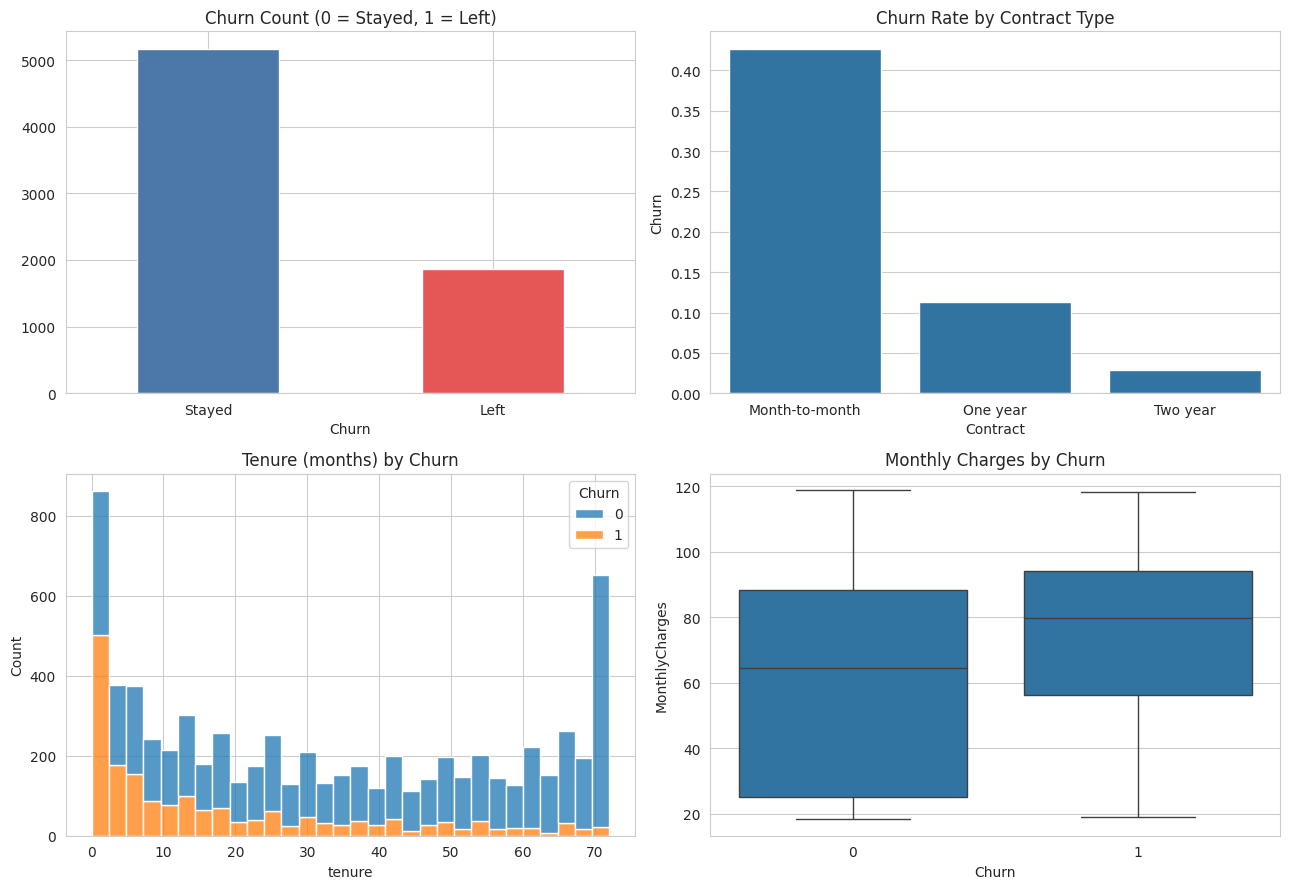

In [10]:
#Step 5: Exploratory Data Analysis (EDA)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Class balance
df["Churn"].value_counts().plot(kind="bar", ax=axes[0, 0], color=["#4C78A8", "#E45756"])
axes[0, 0].set_title("Churn Count (0 = Stayed, 1 = Left)")
axes[0, 0].set_xticklabels(["Stayed", "Left"], rotation=0)

# 2. Churn by contract type
sns.barplot(data=df, x="Contract", y="Churn", ax=axes[0, 1], errorbar=None)
axes[0, 1].set_title("Churn Rate by Contract Type")

# 3. Tenure distribution by churn
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[1, 0], multiple="stack")
axes[1, 0].set_title("Tenure (months) by Churn")

# 4. Monthly charges by churn
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[1, 1])
axes[1, 1].set_title("Monthly Charges by Churn")

plt.tight_layout()
plt.show()

In [11]:
#Step 6: Feature Engineering and Preprocessing
# One-hot encode all text (categorical) columns
X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True)
y = df["Churn"]
print("Features after encoding:", X.shape[1])

# 80% train, 20% test. stratify keeps the same churn ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features (important for Logistic Regression and the neural network)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train size:", X_train.shape, "| Test size:", X_test.shape)

Features after encoding: 30
Train size: (5634, 30) | Test size: (1409, 30)


In [12]:
#Step 7: Machine Learning Models
def evaluate(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
    }

results = []

# Model 1: Logistic Regression (baseline)
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced")
log_reg.fit(X_train_s, y_train)
lr_pred = log_reg.predict(X_test_s)
lr_prob = log_reg.predict_proba(X_test_s)[:, 1]
results.append(evaluate("Logistic Regression", y_test, lr_pred, lr_prob))

# Model 2: Random Forest
rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                            class_weight="balanced", random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
rf_prob = rf.predict_proba(X_test)[:, 1]
results.append(evaluate("Random Forest", y_test, rf_pred, rf_prob))

pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.740,0.507,0.786,0.616,0.841
1,Random Forest,0.757,0.529,0.786,0.632,0.844


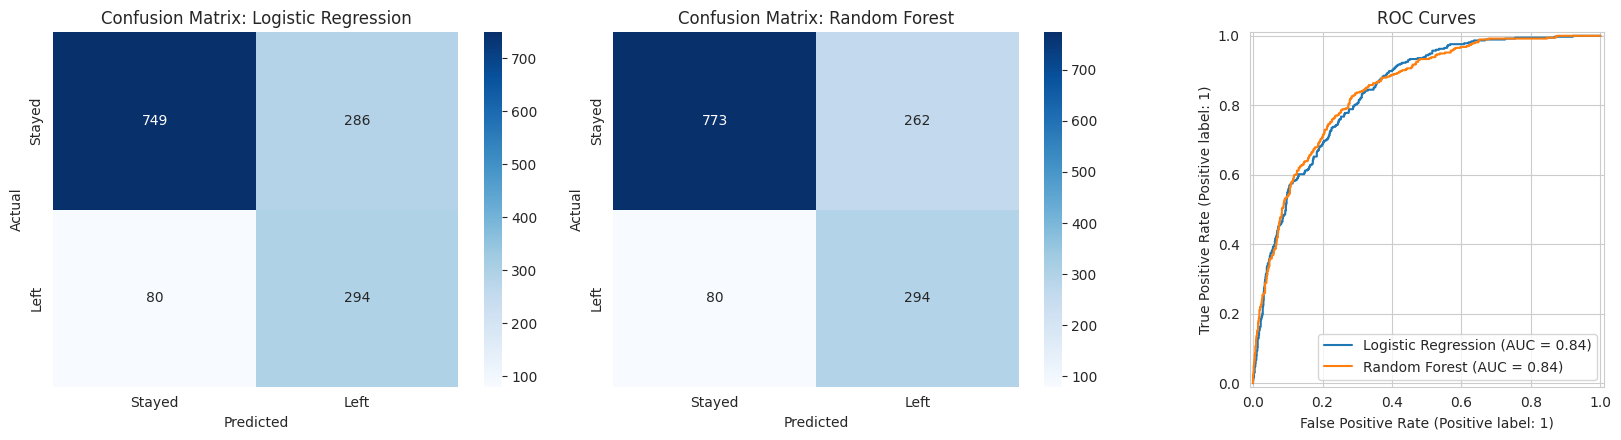

              precision    recall  f1-score   support

      Stayed       0.91      0.75      0.82      1035
        Left       0.53      0.79      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



In [13]:
#Step 8: Model Evaluation
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, (name, pred) in zip(axes[:2], [("Logistic Regression", lr_pred), ("Random Forest", rf_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Stayed", "Left"], yticklabels=["Stayed", "Left"])
    ax.set_title(f"Confusion Matrix: {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

RocCurveDisplay.from_predictions(y_test, lr_prob, name="Logistic Regression", ax=axes[2])
RocCurveDisplay.from_predictions(y_test, rf_prob, name="Random Forest", ax=axes[2])
axes[2].set_title("ROC Curves")
plt.tight_layout()
plt.show()

print(classification_report(y_test, rf_pred, target_names=["Stayed", "Left"]))


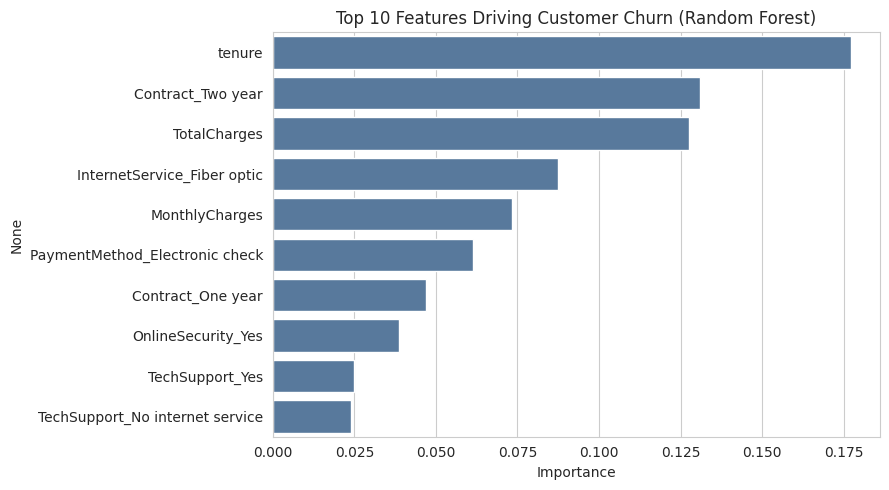

In [14]:
#Step 9: Feature Importance (Business Insight)
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
sns.barplot(x=importances.values, y=importances.index, color="#4C78A8")
plt.title("Top 10 Features Driving Customer Churn (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [15]:
#Step 10: Deep Learning with Keras
model = keras.Sequential([
    layers.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
model.summary()

# Handle class imbalance by giving churners a higher weight
neg, pos = np.bincount(y_train)
class_weight = {0: 1.0, 1: neg / pos}

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10,
                                           restore_best_weights=True)

history = model.fit(X_train_s, y_train,validation_split=0.2,epochs=100, batch_size=32,class_weight=class_weight,callbacks=[early_stop],verbose=0)
print("Training stopped after", len(history.history["loss"]), "epochs")

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

Training stopped after 22 epochs


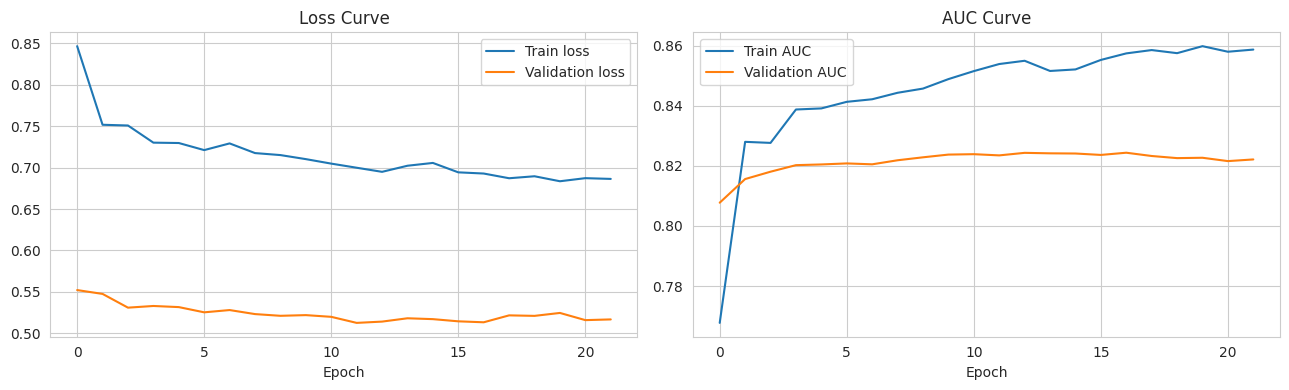

In [16]:
#Step 11: Evaluate the Neural Network
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history.history["loss"], label="Train loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Loss Curve"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(history.history["auc"], label="Train AUC")
axes[1].plot(history.history["val_auc"], label="Validation AUC")
axes[1].set_title("AUC Curve"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

nn_prob = model.predict(X_test_s, verbose=0).ravel()
nn_pred = (nn_prob >= 0.5).astype(int)
results.append(evaluate("Neural Network (Keras)", y_test, nn_pred, nn_prob))

                        Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                              
Logistic Regression        0.740      0.507   0.786  0.616    0.841
Random Forest              0.757      0.529   0.786  0.632    0.844
Neural Network (Keras)     0.745      0.513   0.770  0.616    0.836


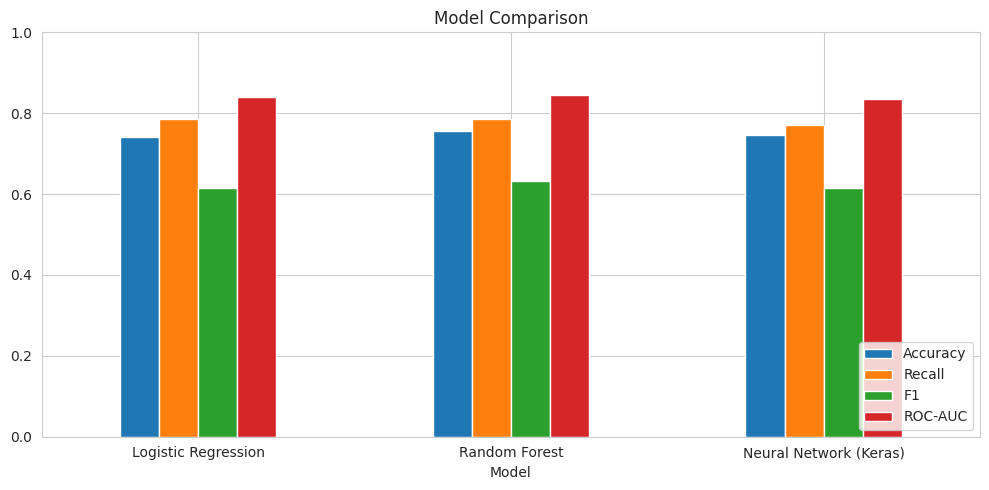

In [17]:
#Step 12: Compare All Models
comparison = pd.DataFrame(results).set_index("Model").round(3)
print(comparison)

comparison[["Accuracy", "Recall", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(10, 5), rot=0)
plt.title("Model Comparison")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [18]:
#Step 13: Predict for a New Customer and Save the Model
import joblib

# Take one customer from the test set as an example
sample = X_test.iloc[[0]]
prob = rf.predict_proba(sample)[0, 1]
print(f"Churn probability: {prob:.1%}")
print("Prediction:", "Will churn - send retention offer" if prob >= 0.5 else "Likely to stay")

# Save models and scaler so they can be reused without retraining
joblib.dump(rf, "churn_random_forest.pkl")
joblib.dump(scaler, "scaler.pkl")
model.save("churn_neural_network.keras")
print("Models saved.")

Churn probability: 5.2%
Prediction: Likely to stay
Models saved.


In [19]:
#Step 14: Conclusion and Recommendations
print("""
KEY FINDINGS
1. About 26.5% of customers churned.
2. Month-to-month contracts, short tenure and high monthly charges are the strongest churn signals.
3. Best models reach roughly 0.84 ROC-AUC on unseen data.

RECOMMENDATIONS
1. Offer discounts or upgrades to move month-to-month customers to 1- or 2-year plans.
2. Run an onboarding programme for customers in their first 12 months.
3. Use the model's churn probability to prioritise retention calls.
""")


KEY FINDINGS
1. About 26.5% of customers churned.
2. Month-to-month contracts, short tenure and high monthly charges are the strongest churn signals.
3. Best models reach roughly 0.84 ROC-AUC on unseen data.

RECOMMENDATIONS
1. Offer discounts or upgrades to move month-to-month customers to 1- or 2-year plans.
2. Run an onboarding programme for customers in their first 12 months.
3. Use the model's churn probability to prioritise retention calls.

